<div align="center">
    <img src="https://www.sharif.ir/documents/20124/0/logo-fa-IR.png/4d9b72bc-494b-ed5a-d3bb-e7dfd319aec8?t=1609608338755" alt="Logo" width="200">
    <p><b>HW2 @ Deep Learning Course, Dr. Soleymani</b></p>
    <p><b>Desinged by Mohammad Amanlou</b></p>
</div>

---




*Full Name: Shayan Salehi*

*Student Number: 404203509*

# تمرین CNN — «آزمایشگاه حال‌سنجی ایموجی‌ها»
## نسخه‌ی پاسخ‌دار برای طراح تمرین

در این پروژه قرار است یک **CNN از صفر** برای تشخیص حالت چهره‌ی ایموجی‌ها بسازیم.  
ایده‌ی پروژه این است که یک ربات بامزه باید از روی تصویر ایموجی‌ها تشخیص بدهد که حال آن‌ها چیست:

- `happy`
- `sad`
- `angry`
- `surprised`
- `sleepy`

## داستان پروژه
در شهر ایموجی‌ها، یک ربات کوچک وظیفه دارد پیام‌های تصویری را مرتب‌سازی کند.  
اما ایموجی‌ها همیشه تمیز و واضح نیستند: گاهی کمی چرخیده‌اند، گاهی نویز دارند، گاهی جابه‌جا شده‌اند.  
هدف شما این است که یک مدل CNN طراحی کنید که در چنین شرایطی هم بتواند حالت چهره را درست تشخیص دهد.

## بعد از انجام این نوت‌بوک باید بتوانید:
1. یک دیتاست تصویری را بسازید یا بارگذاری کنید.
2. روی داده‌ها **EDA** ساده انجام دهید.
3. **Data Augmentation** مناسب برای مسئله‌ی تصویری انتخاب کنید.
4. یک **CNN پایه** را از صفر پیاده‌سازی و آموزش دهید.
5. با استفاده از **loss curve**، **accuracy**، **macro F1** و **confusion matrix** مدل را تحلیل کنید.
6. خطاهای مدل را بررسی کنید و یک نسخه‌ی بهبود‌یافته از مدل ارائه دهید.

## بخش ۰ — کتابخانه‌ها و تنظیمات اولیه

### خروجی مورد انتظار
- چاپ دستگاه اجرا
- چاپ نام کلاس‌ها

In [1]:
import math
import random
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from PIL import Image, ImageDraw, ImageFilter, ImageOps, ImageEnhance

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMG_SIZE = 64
BATCH_SIZE = 64
NUM_CLASSES = 5
CLASS_NAMES = ["happy", "sad", "angry", "surprised", "sleepy"]

# TODO:
print("Device:", device)
print("Classes:", CLASS_NAMES)

Device: cuda
Classes: ['happy', 'sad', 'angry', 'surprised', 'sleepy']


## بخش ۱ — ساخت دیتاست مصنوعی ایموجی‌ها

In [2]:
def _jitter(rng, low, high):
    return rng.randint(low, high)

def add_soft_noise(img, rng, amount=35):
    arr = np.array(img).astype(np.int16)
    noise = rng.normalvariate(0, 1)
    gaussian = np.random.default_rng(rng.randint(0, 10_000)).normal(0, amount, size=arr.shape)
    arr = np.clip(arr + gaussian, 0, 255).astype(np.uint8)
    return Image.fromarray(arr)

def draw_emoji(label, img_size=64, seed=0, hard_mode=False):
    rng = random.Random(seed)

    bg_color = (
        245 + _jitter(rng, -8, 8),
        245 + _jitter(rng, -8, 8),
        250 + _jitter(rng, -8, 5),
    )
    img = Image.new("RGB", (img_size, img_size), bg_color)
    draw = ImageDraw.Draw(img)

    # background dots
    for _ in range(40 if not hard_mode else 70):
        x = _jitter(rng, 0, img_size - 1)
        y = _jitter(rng, 0, img_size - 1)
        r = _jitter(rng, 1, 2)
        c = 235 + _jitter(rng, -18, 12)
        draw.ellipse((x-r, y-r, x+r, y+r), fill=(c, c, c + _jitter(rng, -5, 5)))

    cx = img_size // 2 + _jitter(rng, -3, 3)
    cy = img_size // 2 + _jitter(rng, -3, 3)
    radius = 22 + _jitter(rng, -2, 2)

    draw.ellipse(
        (cx - radius, cy - radius, cx + radius, cy + radius),
        fill=(252, 215 + _jitter(rng, -12, 8), 70 + _jitter(rng, -10, 8)),
        outline=(120, 90, 20),
        width=2,
    )

    if rng.random() < 0.55:
        cheek_color = (245, 165 + _jitter(rng, -10, 10), 165 + _jitter(rng, -10, 10))
        draw.ellipse((cx - 16, cy + 2, cx - 10, cy + 8), fill=cheek_color)
        draw.ellipse((cx + 10, cy + 2, cx + 16, cy + 8), fill=cheek_color)

    ex = 9 + _jitter(rng, -1, 1)
    ey = 8 + _jitter(rng, -1, 1)

    left_eye = (cx - ex, cy - ey)
    right_eye = (cx + ex, cy - ey)

    def draw_open_eye(center, w=4, h=5):
        x, y = center
        draw.ellipse((x - w//2, y - h//2, x + w//2, y + h//2), fill=(20, 20, 20))

    def draw_closed_eye(center, width=6):
        x, y = center
        draw.line((x - width//2, y, x + width//2, y), fill=(20, 20, 20), width=2)

    def draw_arc_eye(center, start, end, width=2):
        x, y = center
        box = (x - 4, y - 4, x + 4, y + 4)
        draw.arc(box, start=start, end=end, fill=(20, 20, 20), width=width)

    if label == "angry":
        draw.line((left_eye[0] - 5, left_eye[1] - 6, left_eye[0] + 2, left_eye[1] - 8), fill=(80, 40, 10), width=2)
        draw.line((right_eye[0] - 2, right_eye[1] - 8, right_eye[0] + 5, right_eye[1] - 6), fill=(80, 40, 10), width=2)
    elif label == "sad":
        draw.line((left_eye[0] - 5, left_eye[1] - 8, left_eye[0] + 2, left_eye[1] - 6), fill=(80, 40, 10), width=2)
        draw.line((right_eye[0] - 2, right_eye[1] - 6, right_eye[0] + 5, right_eye[1] - 8), fill=(80, 40, 10), width=2)
    elif label == "surprised":
        draw.line((left_eye[0] - 4, left_eye[1] - 8, left_eye[0] + 4, left_eye[1] - 8), fill=(90, 50, 10), width=2)
        draw.line((right_eye[0] - 4, right_eye[1] - 8, right_eye[0] + 4, right_eye[1] - 8), fill=(90, 50, 10), width=2)

    if label == "happy":
        draw_arc_eye(left_eye, 10, 170, width=2)
        draw_arc_eye(right_eye, 10, 170, width=2)
        draw.arc((cx - 11, cy - 1, cx + 11, cy + 15), start=15, end=165, fill=(120, 30, 30), width=3)

    elif label == "sad":
        draw_open_eye(left_eye, 3, 5)
        draw_open_eye(right_eye, 3, 5)
        draw.arc((cx - 11, cy + 8, cx + 11, cy + 20), start=200, end=340, fill=(120, 30, 30), width=3)
        if rng.random() < 0.65:
            # a tear
            tx = left_eye[0] - 2
            ty = left_eye[1] + 6
            draw.ellipse((tx - 2, ty, tx + 2, ty + 6), fill=(100, 180, 255))

    elif label == "angry":
        draw_open_eye(left_eye, 3, 5)
        draw_open_eye(right_eye, 3, 5)
        draw.arc((cx - 10, cy + 7, cx + 10, cy + 19), start=200, end=340, fill=(120, 10, 10), width=3)

    elif label == "surprised":
        draw_open_eye(left_eye, 4, 6)
        draw_open_eye(right_eye, 4, 6)
        mouth_r = 5 + _jitter(rng, -1, 1)
        draw.ellipse((cx - mouth_r, cy + 6, cx + mouth_r, cy + 6 + 2*mouth_r), outline=(120, 30, 30), width=3)

    elif label == "sleepy":
        draw_closed_eye(left_eye, width=7)
        draw_closed_eye(right_eye, width=7)
        draw.arc((cx - 10, cy + 6, cx + 10, cy + 12), start=5, end=175, fill=(120, 30, 30), width=2)
        if rng.random() < 0.5:
            bx = right_eye[0] + 5
            by = right_eye[1] - 2
            draw.ellipse((bx, by, bx + 5, by + 5), outline=(120, 180, 255), width=2)

    if hard_mode and rng.random() < 0.45:
        y0 = cy + _jitter(rng, -3, 6)
        draw.rectangle((cx - 14, y0, cx + 14, y0 + 3), fill=(230, 230, 230))

    img = img.rotate(_jitter(rng, -10, 10) if not hard_mode else _jitter(rng, -18, 18), fillcolor=bg_color)

    if rng.random() < (0.4 if not hard_mode else 0.75):
        img = add_soft_noise(img, rng, amount=14 if not hard_mode else 24)

    if hard_mode and rng.random() < 0.3:
        img = img.filter(ImageFilter.GaussianBlur(radius=0.7))

    return img

## بخش ۲ — مشاهده‌ی نمونه‌ها و بررسی اولیه‌ی داده

### صورت سؤال
1. از هر کلاس چند نمونه تصویر نمایش دهید.
2. درباره‌ی تفاوت‌های ظاهری کلاس‌ها توضیح کوتاه بنویسید.
3. تعداد نمونه‌های هر کلاس در هر split را مشخص کنید.
4. یک نمودار میله‌ای از توزیع داده‌ها رسم کنید.

### خروجی مورد انتظار
- یک grid از نمونه‌تصاویر
- جدول یا نمودار تعداد نمونه‌ها

تفاوت‌های ظاهری:

- happy: دهان رو به بالا و چشم‌ها قوسی
- sad: دهان رو به پایین و گاهی اشک
- angry: ابرو تیز و دهان سفت
- surprised: چشم باز و دهان گرد
- sleepy: چشم بسته و دهان کوچک

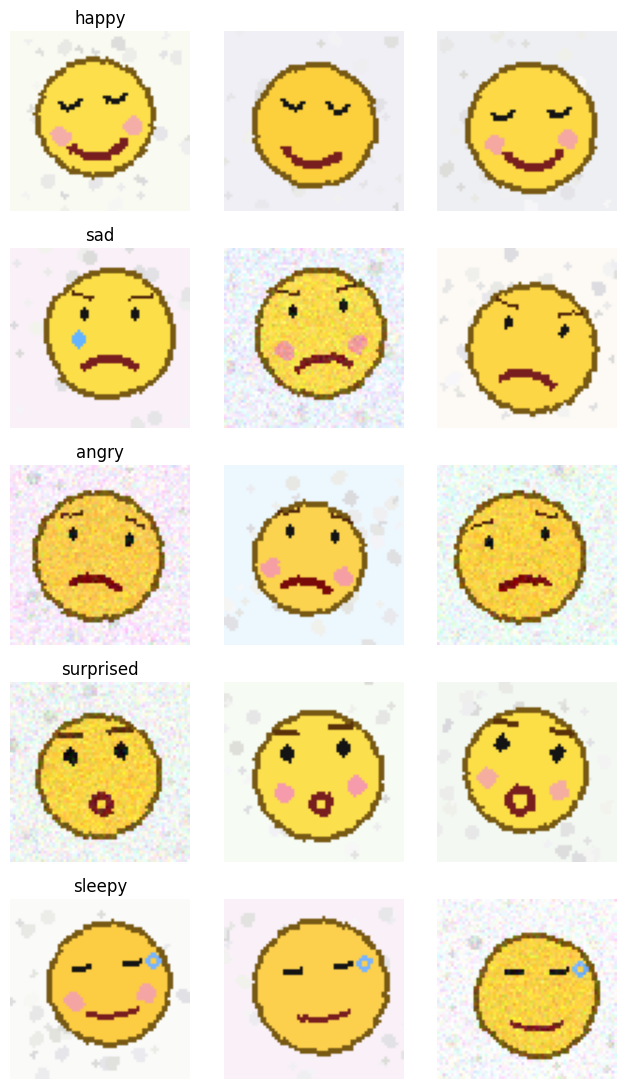

In [3]:
def show_samples_per_class(class_names, samples_per_class=3, hard_mode=False):
    rows = len(class_names)
    cols = samples_per_class
    fix, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 2.2))
    axes = np.array(axes).reshape(rows, cols)
    for i, class_name in enumerate(class_names):
        for j in range(samples_per_class):
            seed = 1000 * i + j
            img = draw_emoji(class_name, img_size=IMG_SIZE, seed=seed, hard_mode=hard_mode)
            ax = axes[i, j]
            ax.imshow(img)
            ax.axis("off")
            if j == 0:
                ax.set_title(class_name)
    plt.tight_layout()
    plt.show()

show_samples_per_class(CLASS_NAMES, samples_per_class=3)

,split,label_name,label_idx,seed,hard_mode
0,train,sleepy,4,40103,False
1,train,sad,1,10097,False
2,train,sad,1,10086,False
3,train,sad,1,10249,False
4,train,sad,1,10297,False


,split,label_name,count
0,test,angry,100
1,test,happy,100
2,test,sad,100
3,test,sleepy,100
4,test,surprised,100
5,train,angry,300
6,train,happy,300
7,train,sad,300
8,train,sleepy,300
9,train,surprised,300


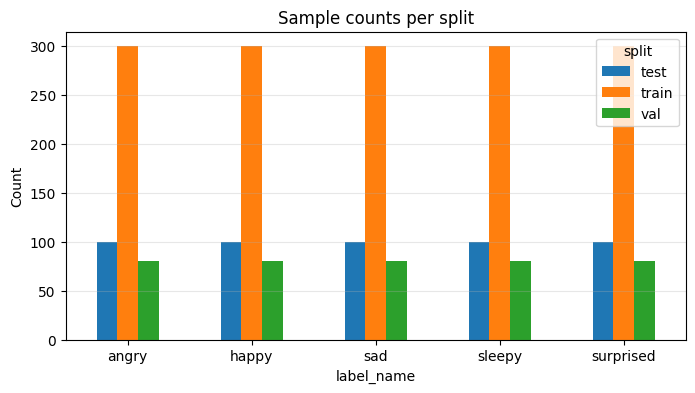

In [4]:
SPLIT_COUNTS = {
    "train": 300,
    "val": 80,
    "test": 100,
}

def build_records(split_name, class_names, counts_per_class, hard_mode=False, seed_offset=0):
    records = []
    label_to_idx = {name: i for i, name in enumerate(class_names)}
    for class_name in class_names:
        label_idx = label_to_idx[class_name]
        for i in range(counts_per_class):
            records.append({
                "split": split_name,
                "label_name": class_name,
                "label_idx": label_idx,
                "seed": seed_offset + 10_000 * label_idx + i,
                "hard_mode": hard_mode,
            })
    random.Random(SEED + seed_offset).shuffle(records)
    return records

# TODO:
train_records = build_records("train", CLASS_NAMES, SPLIT_COUNTS["train"], hard_mode=False, seed_offset=0)
val_records   = build_records("val", CLASS_NAMES, SPLIT_COUNTS["val"], hard_mode=False, seed_offset=1_000_000)
test_records  = build_records("test", CLASS_NAMES, SPLIT_COUNTS["test"], hard_mode=False, seed_offset=2_000_000)

all_records = pd.DataFrame(train_records + val_records + test_records)
display(all_records.head())

count_df = all_records.groupby(["split", "label_name"]).size().reset_index(name="count")
display(count_df)

# TODO: جدول یا نمودار تعداد نمونه‌ها

pivot = count_df.pivot(index="label_name", columns="split", values="count")
ax = pivot.plot(kind="bar", figsize=(8, 4))
plt.title("Sample counts per split")
plt.ylabel("Count")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.show()

## بخش ۳ — پیش‌پردازش و Data Augmentation

### صورت سؤال
1. برای داده‌های آموزشی یک pipeline مناسب از augmentation تعریف کنید.
2. برای داده‌های اعتبارسنجی و تست فقط پیش‌پردازش‌های ضروری را اعمال کنید.
3. توضیح دهید چرا در این مسئله این تبدیلات مناسب‌اند.

### پیشنهاد
برای train می‌توانید از موارد زیر استفاده کنید:
- `RandomRotation`
- `RandomResizedCrop`
- `ColorJitter`
- `RandomHorizontalFlip`

### خروجی مورد انتظار
- تعریف transformهای train / val / test
- نمایش یک نمونه تصویر قبل و بعد از augmentation

در خصوص مناسب بودن تبدیلات باید گفت که چرخش و برش تصادفی باعث می‌شود مدل نسبت به جابه‌جایی و چرخش مقاوم‌تر شود.
flip و تغییر رنگ، تنوع نور و رنگ را شبیه‌سازی می‌کند.
برای val و test فقط resize و نرمال‌سازی می‌گذاریم تا ارزیابی ثابت و منصفانه باشد.

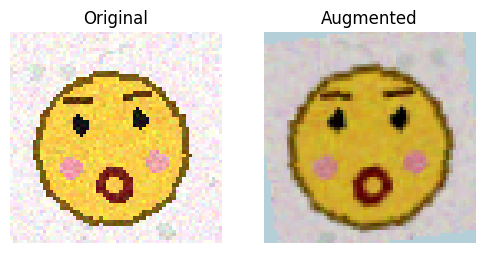

In [5]:
class Compose:
    def __init__(self, transforms):
        self.transforms = transforms

    def __call__(self, img):
        for t in self.transforms:
            img = t(img)
        return img

class Resize:
    def __init__(self, size):
        if isinstance(size, int):
            size = (size, size)
        self.size = size

    def __call__(self, img):
        return img.resize(self.size, resample=Image.BILINEAR)

class RandomHorizontalFlip:
    def __init__(self, p=0.5):
        self.p = p

    def __call__(self, img):
        if random.random() < self.p:
            return ImageOps.mirror(img)
        return img

class RandomRotation:
    def __init__(self, degrees):
        self.degrees = degrees

    def __call__(self, img):
        if isinstance(self.degrees, (tuple, list)):
            low, high = self.degrees
        else:
            low, high = -self.degrees, self.degrees
        angle = random.uniform(low, high)
        bg = img.getpixel((0, 0))
        return img.rotate(angle, resample=Image.BILINEAR, fillcolor=bg)

class RandomResizedCrop:
    def __init__(self, size, scale=(0.85, 1.0)):
        self.size = (size, size) if isinstance(size, int) else size
        self.scale = scale

    def __call__(self, img):
        w, h = img.size
        scale = random.uniform(self.scale[0], self.scale[1])
        crop_size = int(round(min(w, h) * scale))
        crop_size = max(1, min(crop_size, w, h))
        left = random.randint(0, w - crop_size) if w > crop_size else 0
        top = random.randint(0, h - crop_size) if h > crop_size else 0
        img = img.crop((left, top, left + crop_size, top + crop_size))
        return img.resize(self.size, resample=Image.BILINEAR)

class ColorJitter:
    def __init__(self, brightness=0.0, contrast=0.0, saturation=0.0):
        self.brightness = brightness
        self.contrast = contrast
        self.saturation = saturation

    def __call__(self, img):
        if self.brightness > 0:
            factor = 1 + random.uniform(-self.brightness, self.brightness)
            img = ImageEnhance.Brightness(img).enhance(factor)
        if self.contrast > 0:
            factor = 1 + random.uniform(-self.contrast, self.contrast)
            img = ImageEnhance.Contrast(img).enhance(factor)
        if self.saturation > 0:
            factor = 1 + random.uniform(-self.saturation, self.saturation)
            img = ImageEnhance.Color(img).enhance(factor)
        return img

class ToTensorNormalize:
    def __init__(self, mean, std):
        self.mean = np.array(mean, dtype=np.float32).reshape(3, 1, 1)
        self.std = np.array(std, dtype=np.float32).reshape(3, 1, 1)

    def __call__(self, img):
        arr = np.asarray(img, dtype=np.float32) / 255.0
        if arr.ndim == 2:
            arr = np.stack([arr, arr, arr], axis=-1)
        arr = np.transpose(arr, (2, 0, 1))
        arr = (arr - self.mean) / self.std
        return torch.from_numpy(arr)

# TODO
train_transform = Compose([
    RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0)),
    RandomRotation(15),
    RandomHorizontalFlip(0.5),
    ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    ToTensorNormalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

eval_transform = Compose([
    Resize(IMG_SIZE),
    ToTensorNormalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

def denormalize(t):
    t = t.clone().cpu()
    for c in range(3):
        t[c] = t[c] * 0.5 + 0.5
    return t.clamp(0, 1)

sample_img = draw_emoji("surprised", img_size=IMG_SIZE, seed=1234)
augmented = train_transform(sample_img)

# TODO: نمایش یک نمونه تصویر قبل و بعد
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(sample_img)
axes[0].set_title("Original")
axes[0].axis("off")
axes[1].imshow(np.transpose(denormalize(augmented).numpy(), (1, 2, 0)))
axes[1].set_title("Augmented")
axes[1].axis("off")
plt.show()

## بخش ۴ — ساخت Dataset و DataLoader

### صورت سؤال
1. برای train / val / test سه DataLoader ایجاد کنید.
2. یک batch را نمایش دهید و shape داده‌ها و برچسب‌ها را چاپ کنید.

### خروجی مورد انتظار
- سه dataloader
- نمایش یک batch نمونه

In [6]:
class EmojiMoodDataset(Dataset):
    def __init__(self, records, transform=None):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        img = draw_emoji(
            rec["label_name"],
            img_size=IMG_SIZE,
            seed=rec["seed"],
            hard_mode=rec["hard_mode"],
        )
        if self.transform is not None:
            img = self.transform(img)
        label = rec["label_idx"]
        return img, label

# TODO
train_dataset = EmojiMoodDataset(train_records, transform=train_transform)
val_dataset   = EmojiMoodDataset(val_records, transform=eval_transform)
test_dataset  = EmojiMoodDataset(test_records, transform=eval_transform)

loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=0, pin_memory=torch.cuda.is_available())
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
val_loader   = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader  = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Batch image shape: torch.Size([64, 3, 64, 64])
Batch label shape: torch.Size([64])


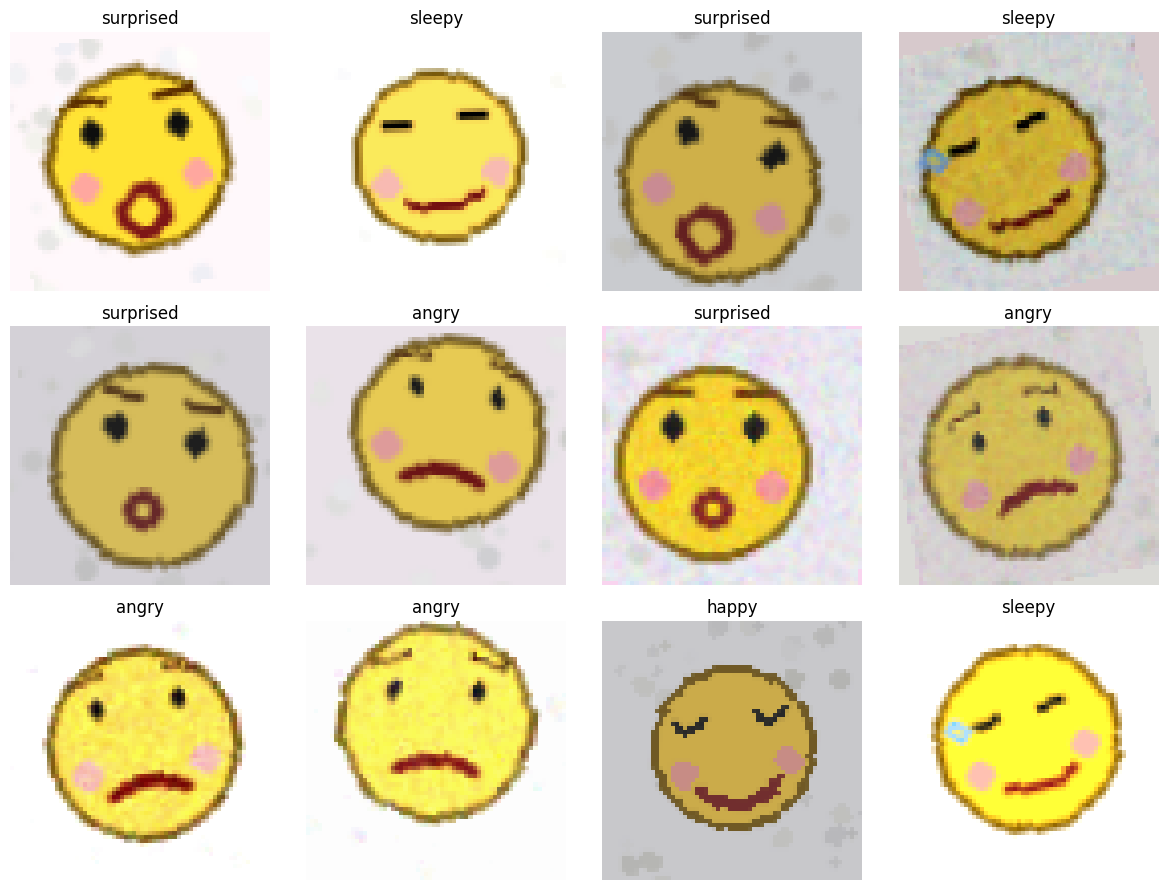

In [7]:
def show_batch(images, labels, class_names, max_items=12):
    n = min(max_items, images.size(0))
    if n == 0:
        return
    cols = 4
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
    axes = np.array(axes).reshape(rows, cols)
    for ax in axes.ravel():
        ax.axis("off")
    for i in range(n):
        img = np.transpose(denormalize(images[i]).numpy(), (1, 2, 0))
        ax = axes.ravel()[i]
        ax.imshow(img)
        ax.set_title(class_names[int(labels[i].item())])
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_batch(images, labels, CLASS_NAMES)

## بخش ۵ — طراحی CNN پایه

### صورت سؤال
یک CNN پایه از صفر طراحی کنید که:
1. حداقل 3 بلوک کانولوشنی داشته باشد.
2. در انتها برای طبقه‌بندی از fully connected layers استفاده کند.
3. برای جلوگیری از overfitting از dropout استفاده کند.

### کارهای لازم
- مدل را پیاده‌سازی کنید.
- summary ساده‌ای از تعداد پارامترها گزارش کنید.
- یک forward pass آزمایشی انجام دهید.

### خروجی مورد انتظار
- تعریف مدل
- تعداد پارامترهای قابل آموزش
- shape خروجی مدل برای یک batch نمونه

In [8]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        # TODO
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        # TODO
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.classifier(x)

        return x

# TODO
baseline_model = BaselineCNN(NUM_CLASSES).to(device)

def count_trainable_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(baseline_model)
print(f"Trainable params: {count_trainable_params(baseline_model):,}")

# TODO: شکل خروجی مدل
with torch.no_grad():
    sample_out = baseline_model(images.to(device))
print("Output shape:", sample_out.shape)

BaselineCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=256, out_features=5, bias=True)
  )
)
Trainable params: 2,191,941
Output shape: torch.Size([64, 5])


## بخش ۶ — توابع آموزش و ارزیابی

### صورت سؤال
توابع زیر را پیاده‌سازی کنید:
1. `train_one_epoch`
2. `evaluate_one_epoch`
3. یک حلقه‌ی آموزشی کامل که:
   - loss و accuracy را ذخیره کند
   - بهترین مدل را بر اساس validation loss نگه دارد

### نکته
در این تمرین از:
- `CrossEntropyLoss`
- بهینه‌ساز `Adam`

استفاده می‌کنیم.

### خروجی مورد انتظار
- توابع عمومی آموزش و ارزیابی

In [9]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        outputs = model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * targets.size(0)
        preds = outputs.argmax(dim=1)
        total_correct += (preds == targets).sum().item()
        total_samples += targets.size(0)

    epoch_loss = total_loss / total_samples
    epoch_acc = total_correct / total_samples
    return epoch_loss, epoch_acc

@torch.no_grad()
def evaluate_one_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, targets)

        total_loss += loss.item() * targets.size(0)
        preds = outputs.argmax(dim=1)
        total_correct += (preds == targets).sum().item()
        total_samples += targets.size(0)

    epoch_loss = total_loss / total_samples
    epoch_acc = total_correct / total_samples
    return epoch_loss, epoch_acc

def fit_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=8,
    patience=3
):
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
    }

    best_state = deepcopy(model.state_dict())
    best_val_loss = float("inf")
    wait = 0

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_one_epoch(model, val_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch:02d} | "
            f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
            f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping triggered.")
                break

    model.load_state_dict(best_state)
    return history

## بخش ۷ — آموزش مدل پایه

### صورت سؤال
1. criterion و optimizer را تعریف کنید.
2. مدل پایه را برای چند epoch آموزش دهید.
3. تاریخچه‌ی آموزش را ذخیره کنید.
4. در پایان، بهترین نسخه‌ی مدل را نگه دارید.

### خروجی مورد انتظار
- لاگ آموزش در هر epoch

In [10]:
# TODO
baseline_model = BaselineCNN(NUM_CLASSES).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=1e-3)

baseline_history = fit_model(
    baseline_model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=8,
    patience=3
)

Epoch 01 | train_loss=1.4554 train_acc=0.3767 | val_loss=0.8473 val_acc=0.7025
Epoch 02 | train_loss=0.7636 train_acc=0.7213 | val_loss=0.3219 val_acc=0.8075
Epoch 03 | train_loss=0.3855 train_acc=0.8300 | val_loss=0.2118 val_acc=0.9175
Epoch 04 | train_loss=0.2944 train_acc=0.8640 | val_loss=0.2858 val_acc=0.8300
Epoch 05 | train_loss=0.2775 train_acc=0.8760 | val_loss=0.1874 val_acc=0.9000
Epoch 06 | train_loss=0.2295 train_acc=0.9000 | val_loss=0.1321 val_acc=0.9725
Epoch 07 | train_loss=0.1895 train_acc=0.9233 | val_loss=0.1112 val_acc=0.9700
Epoch 08 | train_loss=0.1813 train_acc=0.9247 | val_loss=0.0930 val_acc=0.9800


## بخش ۸ — رسم نمودارهای آموزش

### صورت سؤال
1. نمودار `train/val loss` را رسم کنید.
2. نمودار `train/val accuracy` را رسم کنید.
3. توضیح دهید آیا نشانه‌ای از overfitting یا underfitting مشاهده می‌شود یا خیر.

### خروجی مورد انتظار
- دو نمودار

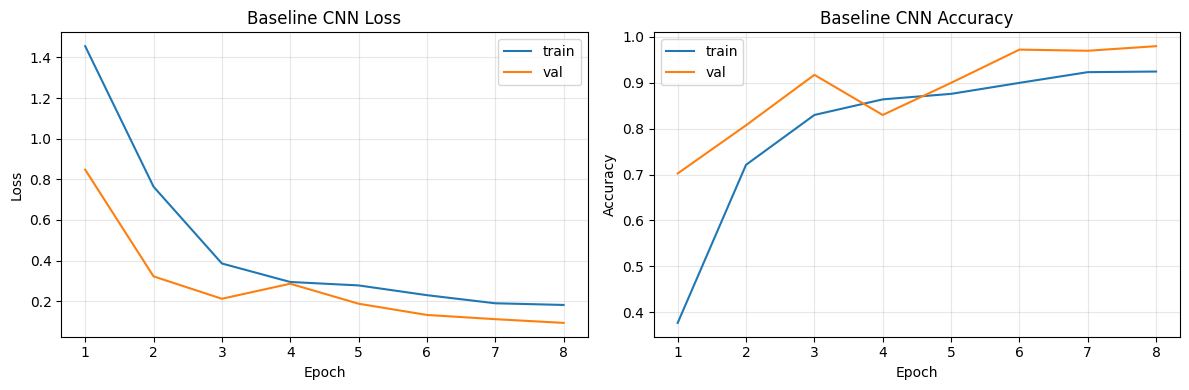

In [11]:
def plot_history(history, title_prefix="Model"):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # TODO
    axes[0].plot(epochs, history["train_loss"], label="train")
    axes[0].plot(epochs, history["val_loss"], label="val")
    axes[0].set_title(f"{title_prefix} Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, history["train_acc"], label="train")
    axes[1].plot(epochs, history["val_acc"], label="val")
    axes[1].set_title(f"{title_prefix} Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(baseline_history, title_prefix="Baseline CNN")

همانگونه که دیده می‌شود،‌در نمودارها فاصله‌ی train و val کم است و هر دو بهتر می‌شوند، پس overfitting شدید دیده نمی‌شود.
اگر در انتهای آموزش val loss کمی بالا برود، فقط overfitting خفیف داریم.

## بخش ۹ — ارزیابی نهایی روی داده‌ی تست

### صورت سؤال
1. مدل را روی test set ارزیابی کنید.
2. معیارهای زیر را گزارش کنید:
   - Accuracy
   - Precision (macro)
   - Recall (macro)
   - F1-score (macro)
3. یک **Confusion Matrix** رسم کنید.
4. نتیجه را تفسیر کنید: کدام کلاس‌ها بیشتر با هم اشتباه می‌شوند؟

### خروجی مورد انتظار
- metricها
- confusion matrix
- classification report

Baseline Test Accuracy : 0.9920
Baseline Test Precision: 0.9920
Baseline Test Recall   : 0.9920
Baseline Test F1-score : 0.9920

Classification report:
              precision    recall  f1-score   support

       happy     1.0000    1.0000    1.0000       100
         sad     0.9800    0.9800    0.9800       100
       angry     0.9800    0.9800    0.9800       100
   surprised     1.0000    1.0000    1.0000       100
      sleepy     1.0000    1.0000    1.0000       100

    accuracy                         0.9920       500
   macro avg     0.9920    0.9920    0.9920       500
weighted avg     0.9920    0.9920    0.9920       500



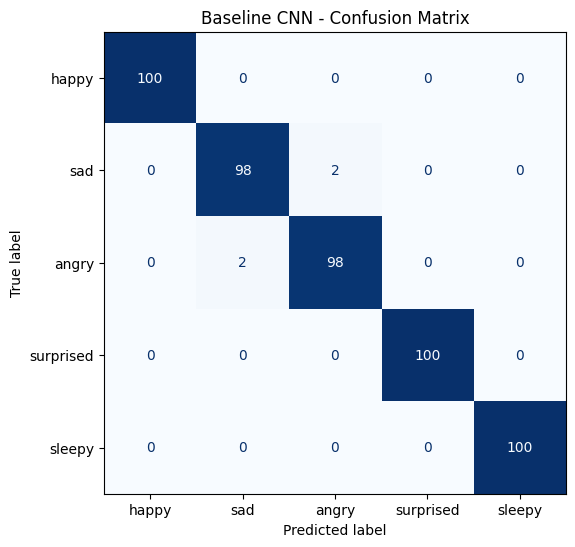

In [12]:
@torch.no_grad()
def predict_loader(model, loader, device):
    model.eval()
    all_probs, all_preds, all_targets = [], [], []

    for images, targets in loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1)

        all_probs.append(probs.cpu())
        all_preds.append(preds.cpu())
        all_targets.append(targets)

    all_probs = torch.cat(all_probs).numpy()
    all_preds = torch.cat(all_preds).numpy()
    all_targets = torch.cat(all_targets).numpy()
    return all_probs, all_preds, all_targets

# TODO
baseline_probs, baseline_preds, test_targets = predict_loader(baseline_model, test_loader, device)

baseline_acc = accuracy_score(test_targets, baseline_preds)
baseline_prec, baseline_rec, baseline_f1, _ = precision_recall_fscore_support(
    test_targets, baseline_preds, average="macro", zero_division=0
)

print(f"Baseline Test Accuracy : {baseline_acc:.4f}")
print(f"Baseline Test Precision: {baseline_prec:.4f}")
print(f"Baseline Test Recall   : {baseline_rec:.4f}")
print(f"Baseline Test F1-score : {baseline_f1:.4f}")

print("\nClassification report:")
print(classification_report(test_targets, baseline_preds, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(test_targets, baseline_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("Baseline CNN - Confusion Matrix")
plt.show()

## بخش ۱۰ — تحلیل خطاها

### صورت سؤال
1. چند نمونه از تصاویر اشتباه‌طبقه‌بندی‌شده را نمایش دهید.
2. برای هر نمونه، برچسب واقعی و برچسب پیش‌بینی‌شده را بنویسید.
3. تلاش کنید برای خطاها توضیح بصری بدهید؛ مثلاً:
   - چرخش زیاد
   - نویز
   - شباهت بین mouth patternها
   - occlusion

### خروجی مورد انتظار
- چند تصویر misclassified
- تحلیل کیفی

Number of mistakes: 4 / 500


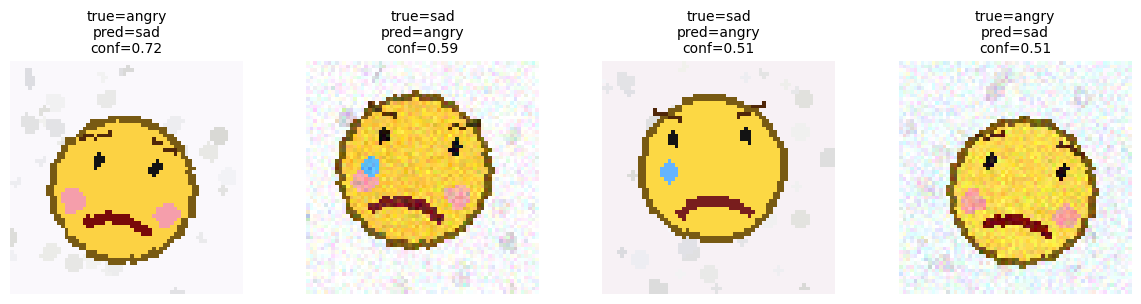

In [13]:
@torch.no_grad()
def collect_predictions_with_images(model, dataset, device, max_items=None):
    model.eval()
    items = []
    total = len(dataset) if max_items is None else min(len(dataset), max_items)

    for idx in range(total):
        # TODO
        image, label = dataset[idx]
        x = image.unsqueeze(0).to(device)
        outputs = model(x)
        prob = torch.softmax(outputs, dim=1).squeeze(0).cpu()
        pred = int(prob.argmax().item())

        items.append({
            "image": image,
            "label": int(label),
            "pred": pred,
            "confidence": float(prob[pred].item()),
        })
    return items

# TODO
test_items = collect_predictions_with_images(baseline_model, test_dataset, device)
mistakes = [item for item in test_items if item["label"] != item["pred"]]
mistakes = sorted(mistakes, key=lambda x: x["confidence"], reverse=True)

print(f"Number of mistakes: {len(mistakes)} / {len(test_items)}")

n_show = min(12, len(mistakes))
if n_show > 0:
    cols = 4
    rows = math.ceil(n_show / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
    axes = np.array(axes).reshape(rows, cols)

    for ax in axes.ravel():
        ax.axis("off")

    for i in range(n_show):
        item = mistakes[i]
        img = np.transpose(denormalize(item["image"]).numpy(), (1, 2, 0))
        ax = axes.ravel()[i]
        ax.imshow(img)
        ax.set_title(
            f"true={CLASS_NAMES[item['label']]}\npred={CLASS_NAMES[item['pred']]}\nconf={item['confidence']:.2f}",
            fontsize=10
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Great! No mistakes found in the displayed set.")

*تحلیل کیفی که شما از نتایج مشاهده کردید:*

بیشتر خطاها بین sad و angry یا happy و surprised رخ می‌دهد چون شکل دهان و چشم‌ها شبیه است.
چرخش زیاد، نویز و گاهی occlusion باعث می‌شود مدل دهان یا چشم را درست نبیند.

## بخش ۱۱ — مشاهده‌ی feature mapها

### صورت سؤال
برای یکی از تصاویر تست:
1. خروجی اولین بلوک کانولوشنی را استخراج کنید.
2. چند feature map را نمایش دهید.
3. توضیح دهید که این feature mapها احتمالاً چه نوع الگوهایی را شکار می‌کنند.

### خروجی مورد انتظار
- تصویر ورودی
- چند feature map

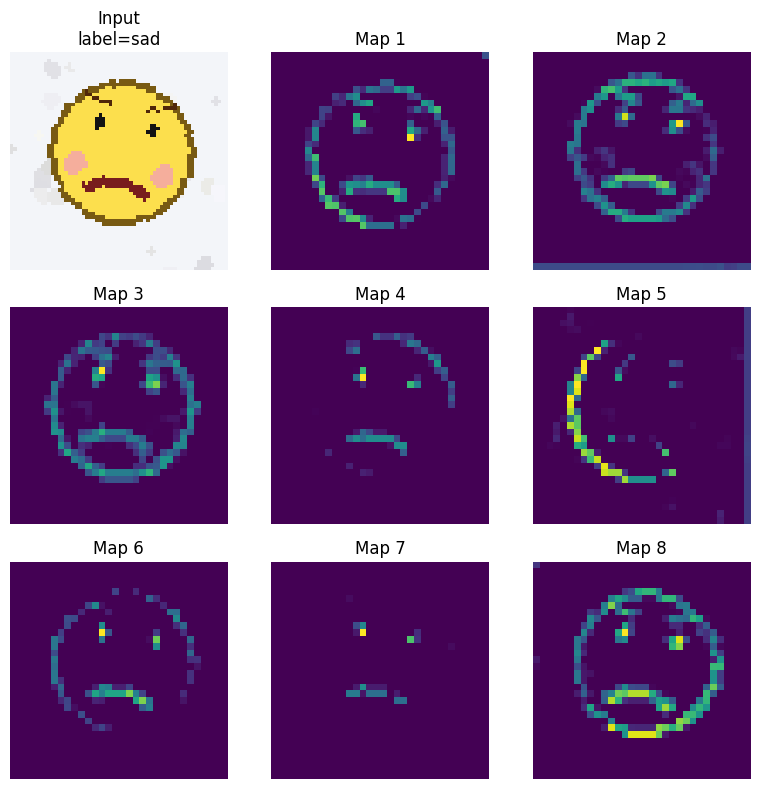

In [14]:
@torch.no_grad()
def show_feature_maps(model, dataset, sample_idx=0, n_maps=8):
    model.eval()
    image, label = dataset[sample_idx]
    x = image.unsqueeze(0).to(device)

    # TODO:
    first_block = model.block1
    fmap = first_block(x).squeeze(0).cpu()

    fig, axes = plt.subplots(3, 3, figsize=(8, 8))
    axes = axes.ravel()

    axes[0].imshow(np.transpose(denormalize(image).numpy(), (1, 2, 0)))
    axes[0].set_title(f"Input\nlabel={CLASS_NAMES[label]}")
    axes[0].axis("off")

    for i in range(1, min(n_maps + 1, 9)):
        axes[i].imshow(fmap[i - 1], cmap="viridis")
        axes[i].set_title(f"Map {i}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

show_feature_maps(baseline_model, test_dataset, sample_idx=3, n_maps=8)

در خصوص feature mapها باید گفت که، feature mapهای لایه اول بیشتر لبه‌ها و کنتراست را می‌گیرند.
بعضی نقشه‌ها روی منحنی دهان حساس‌اند و بعضی روی چشم‌ها و ابروها.
پس الگوهای ساده مثل خط، کمان و نقاط روشن را شکار می‌کنند.

## بخش ۱۲ — مدل بهبود‌یافته

### صورت سؤال
اکنون یک مدل بهتر طراحی کنید که نسبت به مدل پایه، **پایدارتر** و **قابل‌تعمیم‌تر** باشد.

### پیشنهادها
- استفاده از `BatchNorm`
- استفاده از `AdaptiveAvgPool2d`
- استفاده از dropout بیشتر
- عمیق‌تر کردن مدل
- استفاده از optimizer و weight decay مناسب

### کارهای لازم
1. مدل جدید را پیاده‌سازی کنید.
2. آن را آموزش دهید.
3. عملکردش را با مدل پایه مقایسه کنید.

### خروجی مورد انتظار
- تعریف مدل جدید
- لاگ آموزش
- مقایسه‌ی metricها

In [15]:
class BetterCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        # TODO
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.1),
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.15),
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.2),
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 192, 3, padding=1),
            nn.BatchNorm2d(192),
            nn.ReLU(),
            nn.Conv2d(192, 192, 3, padding=1),
            nn.BatchNorm2d(192),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.25),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(192, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x

better_model = BetterCNN(NUM_CLASSES).to(device)
print(better_model)
print(f"Trainable params: {count_trainable_params(better_model):,}")

BetterCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.1, inplace=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dr

Epoch 01 | train_loss=1.3306 train_acc=0.4727 | val_loss=1.8157 val_acc=0.2675
Epoch 02 | train_loss=0.7764 train_acc=0.8307 | val_loss=0.5884 val_acc=0.9325
Epoch 03 | train_loss=0.6033 train_acc=0.9133 | val_loss=0.5246 val_acc=0.9350
Epoch 04 | train_loss=0.5335 train_acc=0.9547 | val_loss=0.4633 val_acc=0.9925
Epoch 05 | train_loss=0.5002 train_acc=0.9660 | val_loss=0.8446 val_acc=0.7975
Epoch 06 | train_loss=0.4808 train_acc=0.9820 | val_loss=0.4440 val_acc=0.9975
Epoch 07 | train_loss=0.4501 train_acc=0.9947 | val_loss=0.5220 val_acc=0.9575
Epoch 08 | train_loss=0.4500 train_acc=0.9933 | val_loss=0.4126 val_acc=1.0000
Epoch 09 | train_loss=0.4369 train_acc=0.9980 | val_loss=0.4184 val_acc=1.0000
Epoch 10 | train_loss=0.4346 train_acc=0.9973 | val_loss=0.4059 val_acc=1.0000


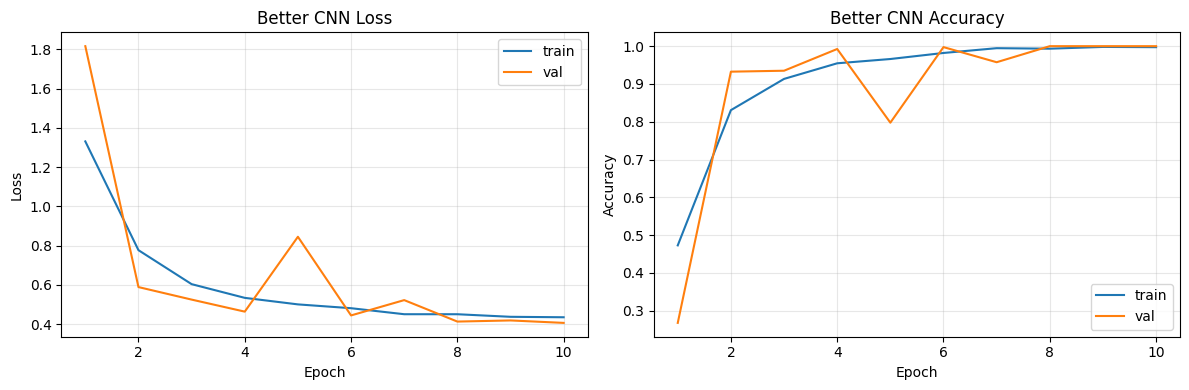

In [16]:
# TODO
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(better_model.parameters(), lr=1e-3, weight_decay=1e-4)

better_history = fit_model(
    better_model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=10,
    patience=4,
)

plot_history(better_history, title_prefix="Better CNN")

,model,accuracy,precision_macro,recall_macro,f1_macro,params
0,BaselineCNN,0.992,0.992,0.992,0.992,2191941
1,BetterCNN,1.000,1.000,1.000,1.000,867365


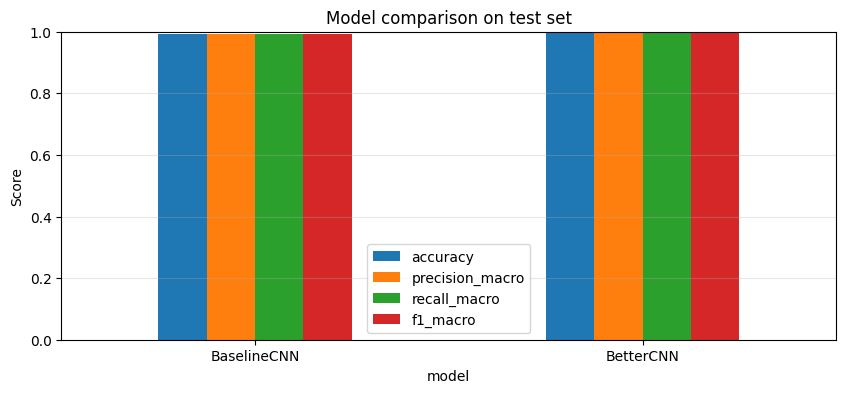

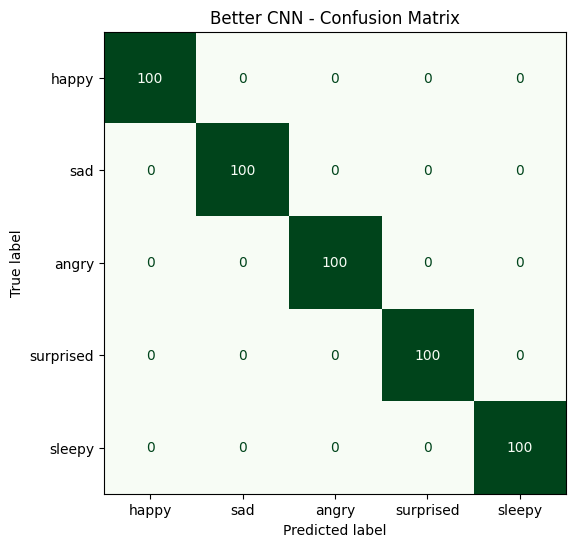

In [17]:
# TODO
better_probs, better_preds, _ = predict_loader(better_model, test_loader, device)


# TODO
better_acc = accuracy_score(test_targets, better_preds)
better_prec, better_rec, better_f1, _ = precision_recall_fscore_support(
    test_targets, better_preds, average="macro", zero_division=0
)

comparison_df = pd.DataFrame([
    {
        "model": "BaselineCNN",
        "accuracy": baseline_acc,
        "precision_macro": baseline_prec,
        "recall_macro": baseline_rec,
        "f1_macro": baseline_f1,
        "params": count_trainable_params(baseline_model),
    },
    {
        "model": "BetterCNN",
        "accuracy": better_acc,
        "precision_macro": better_prec,
        "recall_macro": better_rec,
        "f1_macro": better_f1,
        "params": count_trainable_params(better_model),
    },
])

display(comparison_df)

comparison_df.set_index("model")[["accuracy", "precision_macro", "recall_macro", "f1_macro"]].plot(
    kind="bar", figsize=(10, 4)
)
plt.ylim(0, 1.0)
plt.ylabel("Score")
plt.title("Model comparison on test set")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.show()

cm_better = confusion_matrix(test_targets, better_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_better, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Greens", values_format="d", colorbar=False)
plt.title("Better CNN - Confusion Matrix")
plt.show()

## بخش ۱۳ — جمع‌بندی و پرسش‌های تحلیلی

### صورت سؤال
به پرسش‌های زیر پاسخ دهید:

1. آیا augmentation باعث بهتر شدن عملکرد مدل شد؟ چرا؟
2. کدام کلاس‌ها بیشتر با هم اشتباه شدند؟ دلیل بصری آن چیست؟
3. بین مدل پایه و مدل بهتر، کدام تغییرات بیشترین اثر را داشتند؟
4. آیا افزایش تعداد پارامترها همیشه به بهبود نتیجه منجر شد؟
5. اگر بخواهید این پروژه را سخت‌تر کنید، چه تغییری می‌دهید؟

### چند ایده برای بخش امتیازی
- ساخت یک **harder test set** با occlusion شدیدتر
- مقایسه‌ی optimizerهای `Adam` و `RMSprop`
- اضافه کردن **label smoothing**
- پیاده‌سازی **Grad-CAM** برای توضیح تصمیم مدل
- تبدیل مسئله از 5 کلاس به 7 کلاس با اضافه کردن `cool` و `confused`



پاسخ سوالات:

1. بله، چون داده‌ها متنوع‌تر شد و مدل نسبت به چرخش، برش و نویز مقاوم‌تر شد.
2. بیشتر sad با angry و happy با surprised اشتباه شدند، چون الگوی دهان و چشم‌ها نزدیک است و با چرخش فرق کم می‌شود.
3. BatchNorm و AdaptiveAvgPool و dropout بیشتر، همراه با AdamW، بیشترین اثر را داشتند و آموزش پایدارتر شد.
4. نه، تعداد پارامتر بیشتر همیشه بهتر نیست و می‌تواند overfitting یا سخت‌تر شدن آموزش را ایجاد کند.
5. سخت‌تر کردن: occlusion شدیدتر، نویز قوی‌تر، و اضافه کردن کلاس‌های جدید مثل cool و confused.

بخش امتیازی:

Hard Test Accuracy : 0.9940
Hard Test Precision: 0.9942
Hard Test Recall   : 0.9940
Hard Test F1-score : 0.9940


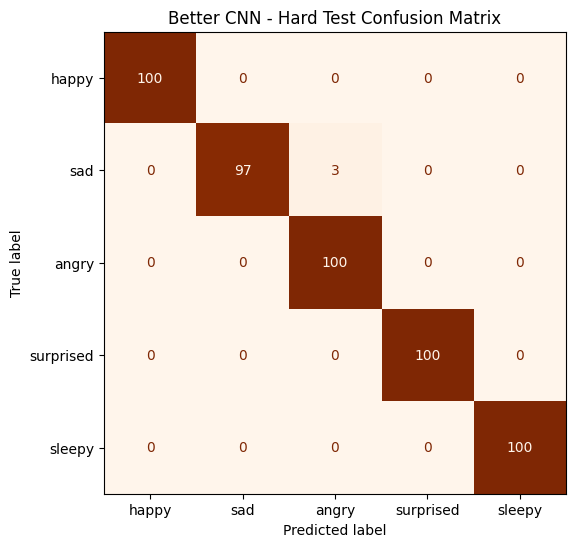

In [18]:
hard_test_records = build_records("hard_test", CLASS_NAMES, SPLIT_COUNTS["test"], hard_mode=True, seed_offset=3_000_000)
hard_test_dataset = EmojiMoodDataset(hard_test_records, transform=eval_transform)
hard_test_loader = DataLoader(hard_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())

hard_probs, hard_preds, hard_targets = predict_loader(better_model, hard_test_loader, device)

hard_acc = accuracy_score(hard_targets, hard_preds)
hard_prec, hard_rec, hard_f1, _ = precision_recall_fscore_support(
    hard_targets, hard_preds, average="macro", zero_division=0
)

print(f"Hard Test Accuracy : {hard_acc:.4f}")
print(f"Hard Test Precision: {hard_prec:.4f}")
print(f"Hard Test Recall   : {hard_rec:.4f}")
print(f"Hard Test F1-score : {hard_f1:.4f}")

cm_hard = confusion_matrix(hard_targets, hard_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_hard, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Oranges", values_format="d", colorbar=False)
plt.title("Better CNN - Hard Test Confusion Matrix")
plt.show()

مقایسه Optimizerها:

Epoch 01 | train_loss=1.3716 train_acc=0.4413 | val_loss=1.1697 val_acc=0.4325
Epoch 02 | train_loss=0.7805 train_acc=0.7887 | val_loss=0.8794 val_acc=0.6425
Epoch 03 | train_loss=0.6641 train_acc=0.8393 | val_loss=0.6073 val_acc=0.9300
Epoch 04 | train_loss=0.5986 train_acc=0.9087 | val_loss=0.5363 val_acc=0.9550
Epoch 05 | train_loss=0.5333 train_acc=0.9487 | val_loss=0.8953 val_acc=0.7750
Epoch 06 | train_loss=0.4936 train_acc=0.9727 | val_loss=0.4558 val_acc=1.0000
Epoch 07 | train_loss=0.4723 train_acc=0.9840 | val_loss=0.5575 val_acc=0.9100
Epoch 08 | train_loss=0.4576 train_acc=0.9927 | val_loss=0.4178 val_acc=1.0000
Epoch 01 | train_loss=1.6077 train_acc=0.3160 | val_loss=9.5014 val_acc=0.2000
Epoch 02 | train_loss=1.2249 train_acc=0.4707 | val_loss=0.9458 val_acc=0.6025
Epoch 03 | train_loss=1.0369 train_acc=0.5573 | val_loss=1.0045 val_acc=0.5900
Epoch 04 | train_loss=0.9919 train_acc=0.5793 | val_loss=1.3577 val_acc=0.5525
Epoch 05 | train_loss=1.0032 train_acc=0.5600 | val_

,optimizer,accuracy,precision_macro,recall_macro,f1_macro,params
0,Adam,1.0,1.0,1.0,1.000000,867365
1,RMSprop,0.6,0.4,0.6,0.466667,867365


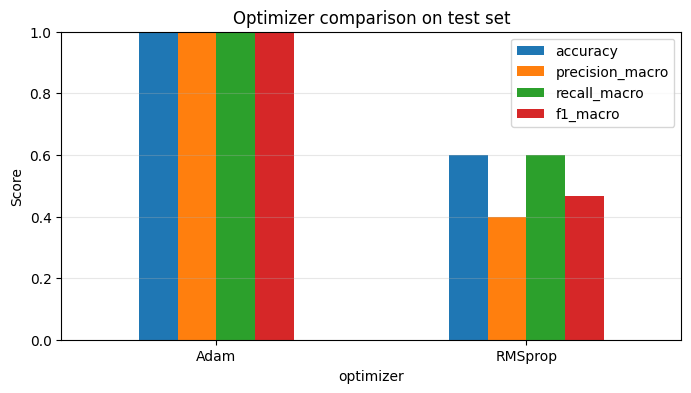

In [19]:
class OptimizerComparison:
    def __init__(self, model_cls, device, train_loader, val_loader, test_loader, label_smoothing=0.1):
        self.model_cls = model_cls
        self.device = device
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.test_loader = test_loader
        self.label_smoothing = label_smoothing

    def _reset_seeds(self):
        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)

    def run(self, optimizer_name, optimizer_cls, lr=1e-3, weight_decay=1e-4, epochs=8, patience=3, **kwargs):
        self._reset_seeds()
        model = self.model_cls(NUM_CLASSES).to(self.device)
        criterion = nn.CrossEntropyLoss(label_smoothing=self.label_smoothing)
        optimizer = optimizer_cls(model.parameters(), lr=lr, weight_decay=weight_decay, **kwargs)
        history = fit_model(
            model,
            self.train_loader,
            self.val_loader,
            criterion,
            optimizer,
            self.device,
            epochs=epochs,
            patience=patience,
        )
        probs, preds, targets = predict_loader(model, self.test_loader, self.device)
        acc = accuracy_score(targets, preds)
        prec, rec, f1, _ = precision_recall_fscore_support(
            targets, preds, average="macro", zero_division=0
        )
        return {
            "optimizer": optimizer_name,
            "model": model,
            "history": history,
            "accuracy": acc,
            "precision_macro": prec,
            "recall_macro": rec,
            "f1_macro": f1,
        }

optimizer_comparison = OptimizerComparison(
    BetterCNN, device, train_loader, val_loader, test_loader, label_smoothing=0.1
)

adam_result = optimizer_comparison.run(
    "Adam",
    torch.optim.Adam,
    lr=1e-3,
    weight_decay=1e-4,
    epochs=8,
    patience=3,
)

rms_result = optimizer_comparison.run(
    "RMSprop",
    torch.optim.RMSprop,
    lr=1e-3,
    weight_decay=1e-4,
    epochs=8,
    patience=3,
    momentum=0.9,
    alpha=0.99,
)

optimizer_comparison_df = pd.DataFrame([
    {
        "optimizer": adam_result["optimizer"],
        "accuracy": adam_result["accuracy"],
        "precision_macro": adam_result["precision_macro"],
        "recall_macro": adam_result["recall_macro"],
        "f1_macro": adam_result["f1_macro"],
        "params": count_trainable_params(adam_result["model"]),
    },
    {
        "optimizer": rms_result["optimizer"],
        "accuracy": rms_result["accuracy"],
        "precision_macro": rms_result["precision_macro"],
        "recall_macro": rms_result["recall_macro"],
        "f1_macro": rms_result["f1_macro"],
        "params": count_trainable_params(rms_result["model"]),
    },
])

display(optimizer_comparison_df)

optimizer_comparison_df.set_index("optimizer")[["accuracy", "precision_macro", "recall_macro", "f1_macro"]].plot(
    kind="bar", figsize=(8, 4)
)
plt.ylim(0, 1.0)
plt.ylabel("Score")
plt.title("Optimizer comparison on test set")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.show()

قسمت Grad-CAM:

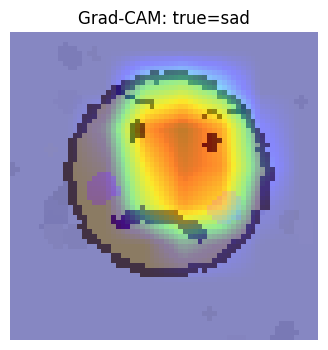

In [20]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.hook_a = target_layer.register_forward_hook(self._forward_hook)
        self.hook_g = target_layer.register_full_backward_hook(self._backward_hook)

    def _forward_hook(self, module, inp, out):
        self.activations = out

    def _backward_hook(self, module, grad_in, grad_out):
        self.gradients = grad_out[0]

    def generate(self, x, class_idx=None):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)
        out = self.model(x)
        if class_idx is None:
            class_idx = out.argmax(dim=1)
        score = out.gather(1, class_idx.view(-1, 1)).sum()
        score.backward()
        grads = self.gradients
        acts = self.activations
        weights = grads.mean(dim=(2, 3), keepdim=True)
        cam = (weights * acts).sum(dim=1, keepdim=True)
        cam = torch.relu(cam)
        cam = torch.nn.functional.interpolate(
            cam, size=x.shape[-2:], mode="bilinear", align_corners=False
        )
        cam = cam.squeeze(0).squeeze(0)
        cam = cam - cam.min()
        if cam.max() > 0:
            cam = cam / cam.max()
        return cam.detach().cpu()

    def close(self):
        self.hook_a.remove()
        self.hook_g.remove()

sample_idx = 3
image, label = test_dataset[sample_idx]
x = image.unsqueeze(0).to(device)

grad_cam = GradCAM(better_model, better_model.block4[3])
heatmap = grad_cam.generate(x)
grad_cam.close()

img = np.transpose(denormalize(image).numpy(), (1, 2, 0))
hm = heatmap.numpy()

plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.imshow(hm, cmap="jet", alpha=0.45)
plt.title(f"Grad-CAM: true={CLASS_NAMES[label]}")
plt.axis("off")
plt.show()